# 03 · The Outlier Problem

**The honest crux.** Quantization maps a range into buckets. A single very large weight
stretches that range, so all the *normal*-sized weights get squeezed into a handful of
buckets and lose the distinctions that mattered. This is the same failure that wrecks a
feature scaler in `scaling_arena`: one outlier hijacks the scale. We show it here as a
measured fact on a matrix with a **planted** outlier, where the truth is known.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "src").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import json
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from src.artifacts import save_figure, save_json
from src.config import load_settings

settings = load_settings()
np.random.seed(settings.seed)
print("settings:", settings.model_dump())

settings: {'seed': 0, 'bit_widths': [8, 4], 'granularity': 'per_channel', 'channel_axis': 1, 'scheme': 'absmax', 'clip_percentile': 99.9, 'clip_sigma': 6.0, 'outlier_sigma': 6.0, 'model_name': 'distilgpt2', 'synthetic': {'rows': 256, 'cols': 256, 'outlier_scale': 10.0, 'n_outliers': 1}}


## A matrix with one planted outlier

Smooth Gaussian weights, plus a single value 50× the largest ordinary magnitude. The
`mask` records exactly where it is, so we can measure the damage to the *ordinary*
weights separately.

ordinary |max| : 0.09463915228843689
outlier value  : 4.73195743560791
range stretched by the outlier: 50x


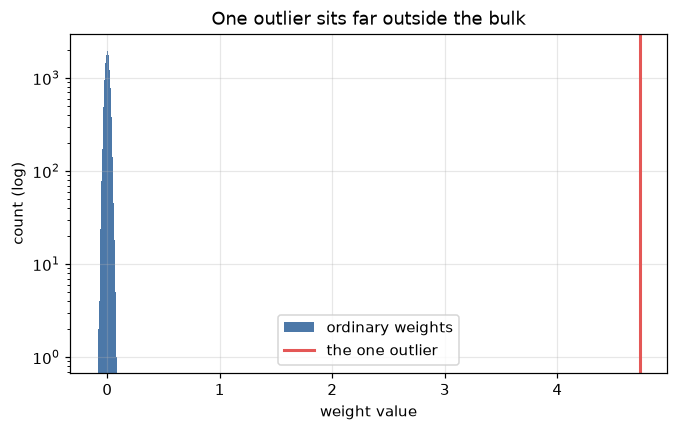

In [2]:
from src.models.weights import planted_outlier_matrix

OUTLIER_SCALE = 50.0
w, mask = planted_outlier_matrix(rows=256, cols=256, outlier_scale=OUTLIER_SCALE, n_outliers=1, seed=0)
ordinary = w[~mask]

print("ordinary |max| :", float(np.abs(ordinary).max()))
print("outlier value  :", float(w[mask][0]))
print("range stretched by the outlier: %.0fx" % (np.abs(w).max() / np.abs(ordinary).max()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ordinary, bins=120, color="#4C78A8", label="ordinary weights")
ax.axvline(float(w[mask][0]), color="#E45756", lw=2, label="the one outlier")
ax.set_yscale("log")
ax.set_xlabel("weight value")
ax.set_ylabel("count (log)")
ax.set_title("One outlier sits far outside the bulk")
ax.legend()
save_figure(fig, "03_outlier_distribution")
plt.show()

## Per-tensor quantization collapses the ordinary weights

With one scale for the whole matrix, the outlier forces the bucket size so wide that the
ordinary weights — which span a tiny fraction of the new range — land on just a few
integer codes. Per-channel scales give each row its own scale, so only the outlier's row
is affected and everyone else keeps full resolution.

distinct int8 codes used by ordinary weights  —  per-tensor: 6 / 256
distinct int8 codes used by ordinary weights  —  per-channel: 255 / 256


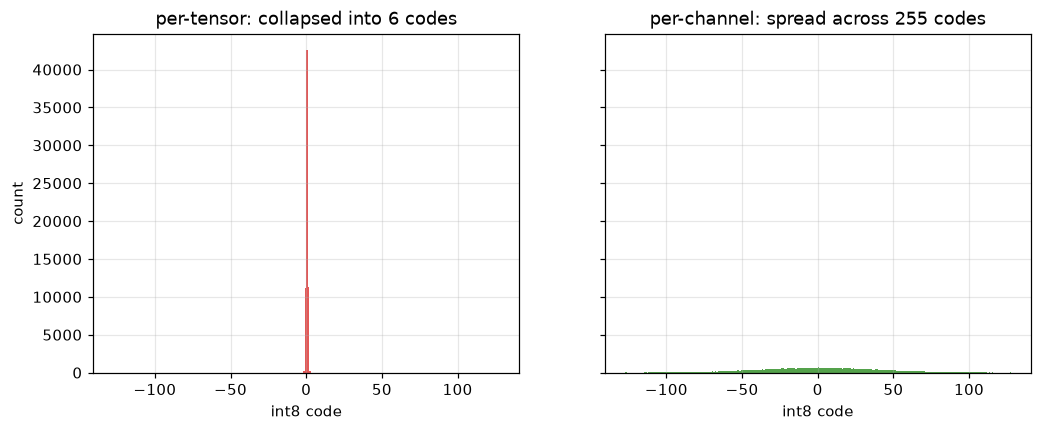

In [3]:
from src.quant.dequant import dequantize
from src.quant.granularity import quantize

qa_tensor = quantize(w, bits=8, scheme="absmax", granularity="per_tensor")
qa_channel = quantize(w, bits=8, scheme="absmax", granularity="per_channel", axis=1)

codes_tensor_ord = qa_tensor.codes[~mask]
codes_channel_ord = qa_channel.codes[~mask]
n_codes_tensor = int(np.unique(codes_tensor_ord).size)
n_codes_channel = int(np.unique(codes_channel_ord).size)

print(f"distinct int8 codes used by ordinary weights  —  per-tensor: {n_codes_tensor} / 256")
print(f"distinct int8 codes used by ordinary weights  —  per-channel: {n_codes_channel} / 256")

fig, (axl, axr) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axl.hist(codes_tensor_ord.ravel(), bins=range(-128, 129), color="#E45756")
axl.set_title(f"per-tensor: collapsed into {n_codes_tensor} codes")
axl.set_xlabel("int8 code")
axl.set_ylabel("count")
axr.hist(codes_channel_ord.ravel(), bins=range(-128, 129), color="#54A24B")
axr.set_title(f"per-channel: spread across {n_codes_channel} codes")
axr.set_xlabel("int8 code")
save_figure(fig, "03_code_collapse")
plt.show()

## The error, measured on the weights that do the work

We measure reconstruction error on the **ordinary** entries only (excluding the outlier
itself). Per-tensor error is many times larger — not because 8 bits is too few, but
because one value hijacked the scale. Per-channel restores it.

int8: ordinary rel error  per-tensor 53.875%  vs  per-channel 3.409%   (16x worse)
int4: ordinary rel error  per-tensor 100.000%  vs  per-channel 14.441%   (7x worse)


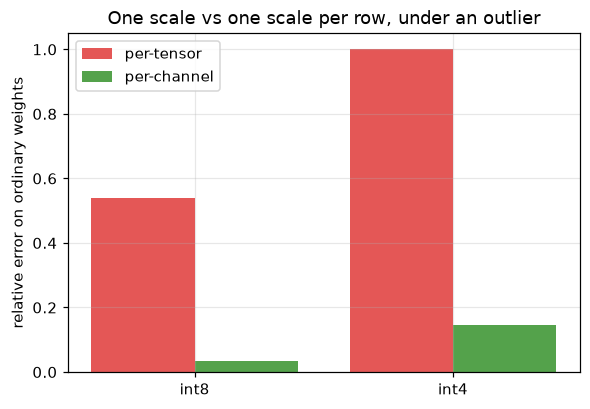

In [4]:
from src.evaluation.reconstruction import reconstruction_error

results = {"outlier_scale": OUTLIER_SCALE,
           "range_stretch": float(np.abs(w).max() / np.abs(ordinary).max()),
           "distinct_codes_ordinary_per_tensor": n_codes_tensor,
           "distinct_codes_ordinary_per_channel": n_codes_channel}

rows = []
for bits in (8, 4):
    e_t = reconstruction_error(ordinary, dequantize(quantize(w, bits=bits, granularity="per_tensor"))[~mask])
    e_c = reconstruction_error(ordinary, dequantize(quantize(w, bits=bits, granularity="per_channel", axis=1))[~mask])
    results[f"ordinary_relerr_int{bits}_per_tensor"] = e_t["rel_fro"]
    results[f"ordinary_relerr_int{bits}_per_channel"] = e_c["rel_fro"]
    results[f"ratio_int{bits}"] = e_t["rel_fro"] / e_c["rel_fro"]
    rows.append((bits, e_t["rel_fro"], e_c["rel_fro"]))
    print(f"int{bits}: ordinary rel error  per-tensor {e_t['rel_fro']:.3%}  vs  per-channel {e_c['rel_fro']:.3%}"
          f"   ({e_t['rel_fro'] / e_c['rel_fro']:.0f}x worse)")

labels = [f"int{b}" for b, _, _ in rows]
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - 0.2, [t for _, t, _ in rows], 0.4, label="per-tensor", color="#E45756")
ax.bar(x + 0.2, [c for _, _, c in rows], 0.4, label="per-channel", color="#54A24B")
ax.set_xticks(x, labels)
ax.set_ylabel("relative error on ordinary weights")
ax.set_title("One scale vs one scale per row, under an outlier")
ax.legend()
save_figure(fig, "03_error_vs_granularity")
plt.show()

## It is a real effect, not just a synthetic one

`distilgpt2`'s own `c_fc` matrix has a heavy tail (largest weight ~37× the typical size).
Per-tensor int4 pays for it; per-channel contains it.

In [5]:
from src.models.weights import load_model_weights

real = load_model_weights(settings.model_name)
w_real = real[next(k for k in real if k.endswith("mlp.c_fc.weight"))]
e_t = reconstruction_error(w_real, dequantize(quantize(w_real, bits=4, granularity="per_tensor")))
e_c = reconstruction_error(w_real, dequantize(quantize(w_real, bits=4, granularity="per_channel", axis=1)))
results["real_c_fc_int4_per_tensor_relerr"] = e_t["rel_fro"]
results["real_c_fc_int4_per_channel_relerr"] = e_c["rel_fro"]
print(f"real c_fc int4:  per-tensor {e_t['rel_fro']:.3%}  vs  per-channel {e_c['rel_fro']:.3%}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

real c_fc int4:  per-tensor 94.769%  vs  per-channel 21.942%


## Takeaway

Quantization failure is an **outlier-and-scale** problem, not a too-few-bits problem. The
ordinary weights never needed more than 8 (or even 4) bits; they were collapsed by a
single value that stretched the shared scale. Notebook 04 builds the fixes.

In [6]:
path = save_json(results, "03_results")
print("saved", path)
results

saved /workspaces/quantization_101/outputs/data/03_results.json


{'outlier_scale': 50.0,
 'range_stretch': 50.0,
 'distinct_codes_ordinary_per_tensor': 6,
 'distinct_codes_ordinary_per_channel': 255,
 'ordinary_relerr_int8_per_tensor': 0.5387466549873352,
 'ordinary_relerr_int8_per_channel': 0.034087084233760834,
 'ratio_int8': 15.805008468684012,
 'ordinary_relerr_int4_per_tensor': 1.0,
 'ordinary_relerr_int4_per_channel': 0.1444123238325119,
 'ratio_int4': 6.92461677411819,
 'real_c_fc_int4_per_tensor_relerr': 0.9476940631866455,
 'real_c_fc_int4_per_channel_relerr': 0.21941764652729034}